### 1. Importar librerias
Se importan las librerías fundamentales para la manipulación de datos, preprocesamiento, sobremuestreo, modelado y métricas de evaluación. No se incluyen módulos de encadenamiento.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Módulos de scikit-learn
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, 
    classification_report, 
    confusion_matrix, 
    precision_recall_curve,
    roc_curve,
    f1_score
)

# Módulo para el tratamiento del desbalanceo de clases
from imblearn.over_sampling import RandomOverSampler


### 2. Ingesta y Adecuación de los Datos
Se realiza la carga del conjunto de datos, descartando variables de identificación que carecen de poder predictivo. A continuación, se aplica una codificación binaria (*One-Hot Encoding*) a las variables categóricas, omitiendo la primera categoría (`drop_first=True`) para suprimir la multicolinealidad estructural.

In [2]:
# Carga del conjunto de datos (sustituir ruta según entorno)
df = pd.read_csv('Data/df_negocio_valor_presente.csv')

# Eliminación de variables no relevantes
df = df.drop(columns=['ID', 'Proposito'], errors='ignore')

# Transformación de variables categóricas a numéricas
df = pd.get_dummies(df, columns=['Sistema'], drop_first=True)

# Separación de predictores (X) y variable objetivo (y)
X = df.drop(columns=['Impago'])
y = df['Impago']

print(f"Dimensiones de la matriz de características: {X.shape}")
print(f"Distribución original de la variable objetivo:\n{y.value_counts(normalize=True) * 100}")
df.head()

Dimensiones de la matriz de características: (76513, 24)
Distribución original de la variable objetivo:
Impago
0    88.420268
1    11.579732
Name: proportion, dtype: float64


,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Posesion_Hipoteca,...,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Divorciado,Estado_Civil_Soltero,Estudios_Escolar,Estudios_Grado Universitario,Estudios_Máster,Valor_Presente,Valor_Final,Sistema_frances
0,51,56857.0,102886,718,338.0,3,6.18,24.0,0.55,1.0,...,0,0,0,0,0,1,0,53028.01,56399.58,True
1,46,45840.0,30473,689,291.0,1,14.28,36.0,0.34,0.0,...,0,0,0,0,1,0,0,15236.50,18852.20,False
2,36,48156.0,188824,675,161.0,2,13.35,36.0,0.55,0.0,...,1,0,0,1,0,1,0,103781.93,126651.11,True
3,42,41472.0,40000,582,312.0,1,11.83,12.0,0.44,1.0,...,1,0,1,0,1,0,0,20588.43,21836.64,True
4,60,70202.0,40743,652,489.0,2,9.27,48.0,0.25,1.0,...,0,1,0,0,0,1,0,20371.50,24503.70,False


In [3]:
# Se añade la constante (intercepto) requerida por statsmodels
X_sm = sm.add_constant(X)

# Ajuste del modelo Logit
modelo_sm = sm.Logit(y, X_sm).fit()

# Visualización del resumen estadístico
print(modelo_sm.summary())

Optimization terminated successfully.
         Current function value: 0.335640
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 Impago   No. Observations:                76513
Model:                          Logit   Df Residuals:                    76488
Method:                           MLE   Df Model:                           24
Date:                Wed, 28 Oct 2026   Pseudo R-squ.:                 0.06368
Time:                        16:31:54   Log-Likelihood:                -25681.
converged:                       True   LL-Null:                       -27427.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                    -0.9801      

### 3. Partición Estricta del Conjunto de Datos
Para imposibilitar cualquier filtración de información, se segrega el 30% del volumen de datos como conjunto de evaluación (`Test`). Este subconjunto no participará en ninguna fase del ajuste estadístico.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_sm, y, 
    test_size=0.3, 
    random_state=42, 
    stratify=y
)

print(f"Volumen de Entrenamiento: {X_train.shape[0]} observaciones")
print(f"Volumen de Evaluación: {X_test.shape[0]} observaciones")

Volumen de Entrenamiento: 53559 observaciones
Volumen de Evaluación: 22954 observaciones


### 4. Tratamiento del Desbalanceo (Sobremuestreo Manual)
Dado que las clases se encuentran desbalanceadas, se procede a la generación aleatoria de observaciones de la clase minoritaria mediante `RandomOverSampler`. **Esta operación se aplica única y exclusivamente sobre la matriz de entrenamiento**, preservando la integridad del conjunto de prueba.

In [5]:
# Instanciación del remuestreador (ratio 2:1 -> minoritaria es el 50% de mayoritaria)
ros = RandomOverSampler(sampling_strategy=0.5, random_state=42)

# Aplicación del remuestreo estrictamente sobre el conjunto de entrenamiento
X_train_bal, y_train_bal = ros.fit_resample(X_train, y_train)

print("Distribución de la variable objetivo tras el balanceo en Entrenamiento:")
print(y_train_bal.value_counts())

Distribución de la variable objetivo tras el balanceo en Entrenamiento:
Impago
0    47357
1    23678
Name: count, dtype: int64


### 5. Estandarización de Escalas
Los modelos lineales regularizados exigen que las variables continuas operen en la misma magnitud. El algoritmo `StandardScaler` extrae su estructura matemática (medias y desviaciones estándar) del conjunto de entrenamiento balanceado. Posteriormente, proyecta estas reglas sobre el conjunto de evaluación de manera pasiva.

In [6]:
scaler = StandardScaler()

# Aprendizaje de parámetros estadísticos y transformación del entrenamiento
scaler_model = scaler.fit(X_train)

# Transformación aislada del conjunto de prueba
X_test_scaled = scaler_model.transform(X_test)
X_train_scaled = scaler_model.transform(X_train_bal)


### 6. Ajuste del Modelo y Validación Cruzada (Elastic Net)
Se instancia una Regresión Logística configurada con la regularización `Elastic Net` (combinación de penalidades L1 y L2) orientada a mitigar la colinealidad. La optimización de los hiperparámetros se ejecuta mediante validación cruzada (`GridSearchCV`) sobre el espacio bidimensional de `C` y `l1_ratio`.

In [7]:
# Definición del estimador base
modelo_logistico = LogisticRegression(
    penalty='elasticnet', 
    solver='saga', 
    max_iter=2500, 
    random_state=42
)

# Espacio de hiperparámetros a explorar
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'l1_ratio': [0.0, 0.25, 0.5, 0.75, 1.0] # 0.0 (Ridge), 1.0 (Lasso)
}

# Configuración de la validación cruzada estratificada

# Búsqueda exhaustiva orientada a maximizar el F1-Score
grid_search = GridSearchCV(
    estimator=modelo_logistico,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

# Ejecución sobre los datos de entrenamiento procesados
grid_search.fit(X_train_scaled, y_train_bal)

best_model = grid_search.best_estimator_
print("Hiperparámetros óptimos seleccionados:")
print(grid_search.best_params_)

c:\Users\USUARIO\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


Hiperparámetros óptimos seleccionados:
{'C': 0.01, 'l1_ratio': 1.0}


### 7. Calibración del Umbral de Decisión
Con el objetivo de maximizar el balance entre precisión y exhaustividad (`Roc-auc`), se analiza la distribución probabilística generada por el modelo sobre el conjunto de entrenamiento. Se extrae el umbral empírico que desplaza el punto de corte estándar de 0.5.

Umbral óptimo: 0.4055


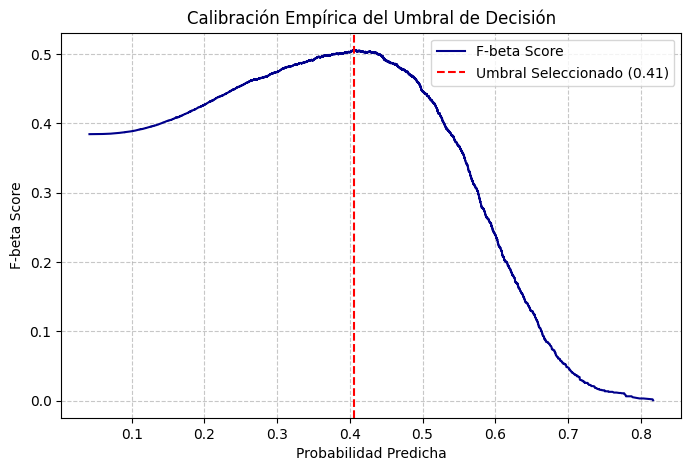

In [8]:
y_train_probs = best_model.predict_proba(X_train_scaled)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_train_bal, y_train_probs)

# F-beta Score con beta = 0.5 para penalizar severamente los Falsos Positivos
beta = 0.5 
fbeta_scores = (1 + beta**2) * (precisions * recalls) / ((beta**2 * precisions) + recalls + 1e-10)

optimal_idx = np.argmax(fbeta_scores)
optimal_threshold = thresholds[optimal_idx]

print(f"Umbral óptimo: {optimal_threshold:.4f}")



# Representación gráfica del comportamiento del umbral
plt.figure(figsize=(8, 5))
plt.plot(thresholds, fbeta_scores[:-1], label='F-beta Score', color='darkblue')
plt.axvline(x=optimal_threshold, color='red', linestyle='--', label=f'Umbral Seleccionado ({optimal_threshold:.2f})')
plt.title('Calibración Empírica del Umbral de Decisión')
plt.xlabel('Probabilidad Predicha')
plt.ylabel('F-beta Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### 8. Evaluación Final de Rendimiento Out-of-Sample
En la etapa culminante, el modelo optimizado proyecta las clasificaciones sobre el conjunto de evaluación (`Test`), el cual ha permanecido estrictamente aislado a lo largo de todo el ciclo de preprocesamiento y entrenamiento.

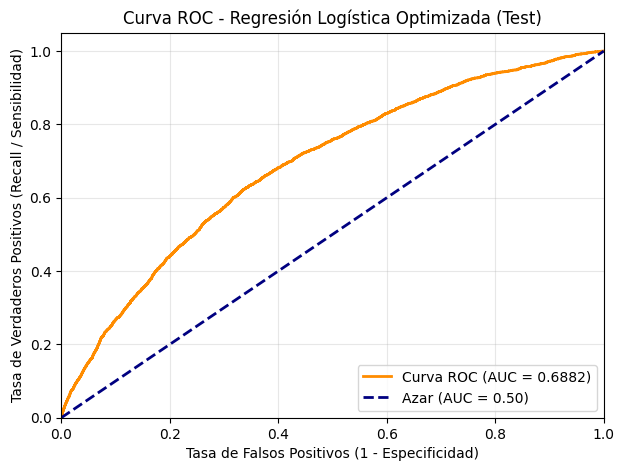

ROC-AUC Final en Test: 0.6882


In [9]:
fpr, tpr, umbrales = roc_curve(y_test, best_model.predict_proba(X_test_scaled)[:, 1])
# AUC debe calcularse con la etiqueta real y las probabilidades del modelo
y_test_probs = best_model.predict_proba(X_test_scaled)[:, 1]
roc_auc_test = roc_auc_score(y_test, y_test_probs)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr,
    tpr,
    color='darkorange',
    lw=2,
    label=f'Curva ROC (AUC = {roc_auc_test:.4f})',
)
plt.plot(
    [0, 1],
    [0, 1],
    color='navy',
    lw=2,
    linestyle='--',
    label='Azar (AUC = 0.50)',
)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (Recall / Sensibilidad)')
plt.title('Curva ROC - Regresión Logística Optimizada (Test)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

print('ROC-AUC Final en Test:', round(roc_auc_test, 4))

--- MATRIZ DE CONFUSIÓN ---


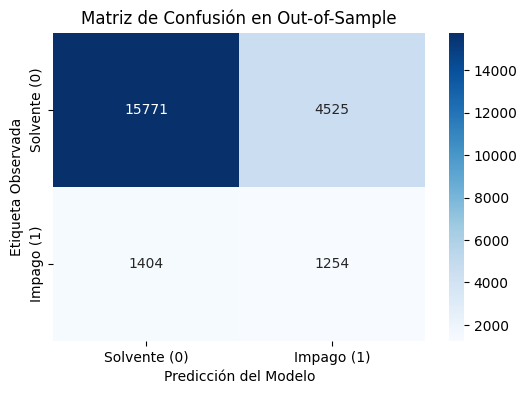


--- REPORTE DE CLASIFICACIÓN ESTADÍSTICA ---
              precision    recall  f1-score   support

Solvente (0)       0.92      0.78      0.84     20296
  Impago (1)       0.22      0.47      0.30      2658

    accuracy                           0.74     22954
   macro avg       0.57      0.62      0.57     22954
weighted avg       0.84      0.74      0.78     22954



In [10]:
# Inferencia de probabilidades sobre el conjunto de evaluación
y_test_probs = best_model.predict_proba(X_test_scaled)[:, 1]

# Asignación de clases empleando el umbral calibrado
y_test_pred = (y_test_probs >= optimal_threshold).astype(int)

# Visualización de la Matriz de Confusión
print("--- MATRIZ DE CONFUSIÓN ---")
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Solvente (0)', 'Impago (1)'], 
            yticklabels=['Solvente (0)', 'Impago (1)'])
plt.ylabel('Etiqueta Observada')
plt.xlabel('Predicción del Modelo')
plt.title('Matriz de Confusión en Out-of-Sample')
plt.show()

# Informe detallado de precisión y exhaustividad
print("\n--- REPORTE DE CLASIFICACIÓN ESTADÍSTICA ---")
print(classification_report(y_test, y_test_pred, target_names=['Solvente (0)', 'Impago (1)']))

### 9. Evaluacion del modelo.
Tras hacer las comprobaciones de (`curva_roc`)y(`matriz de confusion`) junto con(`classification_report`) se puede observar que efectivamente el modelo es mejor que el azar y logra encontrar el **47%** de los impagos y solo acusa al **22%** de los pagadores. Acertando el **92%** de las predicciones de pago y el **22%** de predicciones de impago con un accuracy global de **74%**
